<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/mae5911/p_value.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
# Z ~N(mu, sigma^2)
# H0: mu=m0
# H0: Z ~N(muO, sigma^2), sigma^2>0

[1] 0.002486038

[1] 0.8132

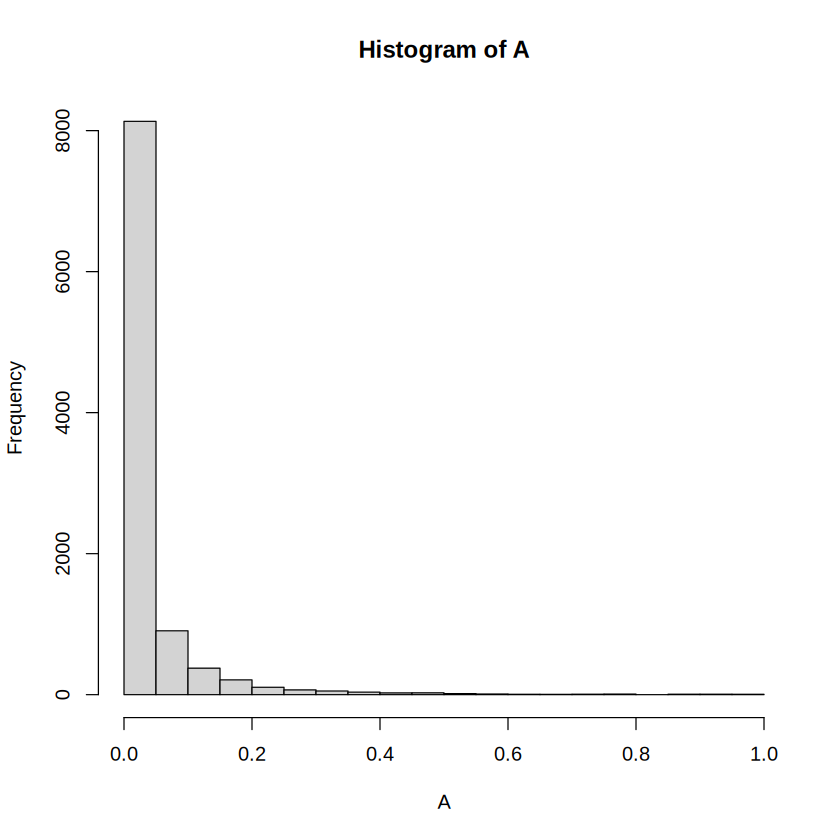

In [61]:
n = 10
mu = 1
sigma2 = 4
MC = 10000
A = numeric()

for(i in 1:MC) {
  z = rnorm(n, mu, sd = sqrt(sigma2))

  # H0 mu =1
  mu0 = 3
  TH0 = n * (mean(z) - mu0)^2/var(z)
  valorp = 1 - pf(TH0, 1, n-1)
  A[i] = valorp
}

hist(A)
valorp
mean(A<0.05)

[1] 0.0531 0.0561 0.0542 0.0554

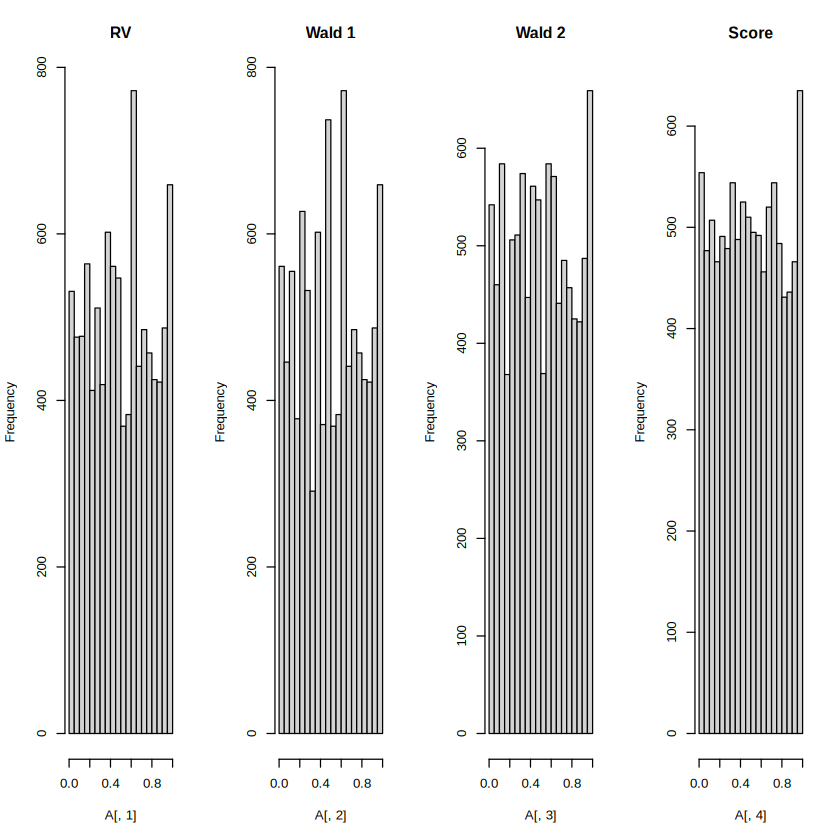

In [62]:
# z ~ poisson
# z ~ Pois(theta), theta>0
# H0: Z ~ Pois(2)

n = 150
theta = 2
MC = 10000
A = matrix(0, MC, 4)

for(i in 1:MC) {
  z = rpois(n, theta)
  theta0=2

  TH0_RV = 2 * theta0 * n-2 * n * mean(z) * (1-log(mean(z)/theta0))
  TH0_W1 = n*(mean(z) - theta0)^2/theta0
  TH0_W2 = n*(mean(z) - theta0)^2/mean(z)
  TH0_S = n*(mean(z) - theta0)^2/var(z)
  valorp.RV = 1 - pchisq(TH0_RV,1)
  valorp.W1 = 1 - pchisq(TH0_W1,1)
  valorp.W2 = 1 - pchisq(TH0_W2,1)
  valorp.S = 1 - pchisq(TH0_S,1)
  A[i,] = c(valorp.RV, valorp.W1, valorp.W2, valorp.S)

}

par(mfrow=c(1,4))
hist(A[,1], main="RV")
hist(A[,2], main="Wald 1")
hist(A[,3], main="Wald 2")
hist(A[,4], main="Score")

colMeans(A<0.05)

[1] 0.2581 0.2643 0.2574 0.0568

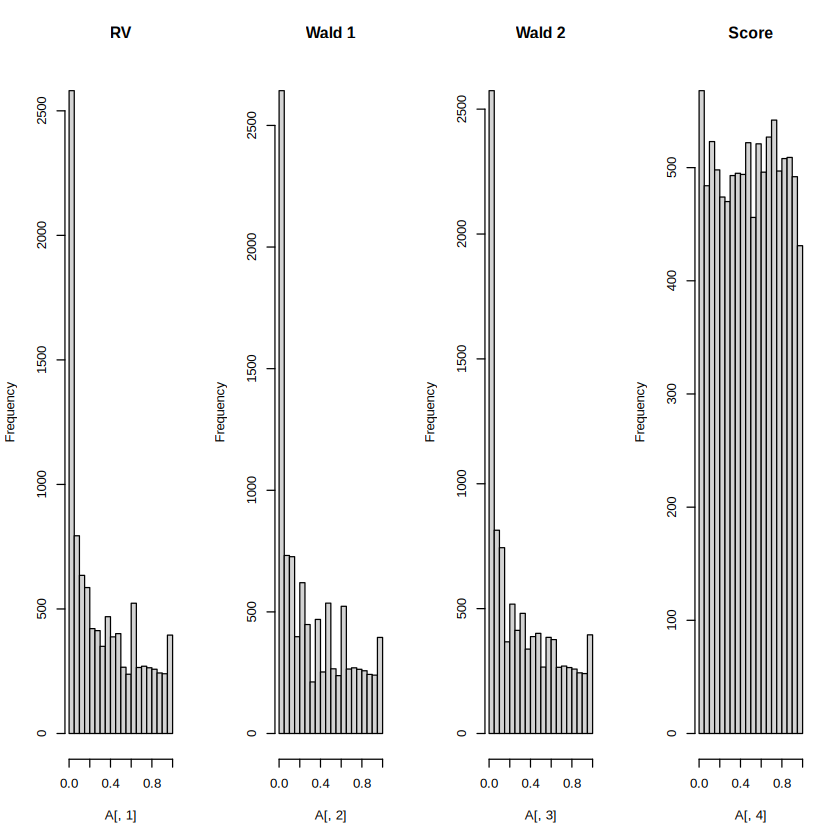

In [66]:
# Negative binomial distribution

# z ~ Negative binomial distribution

n = 150
theta = 2
MC = 10000
A = matrix(0, MC, 4)
theta0 = 2
m = 1

for(i in 1:MC) {
  z = rnbinom(n, size = m, mu = theta)

  TH0_RV = 2 * theta0 * n-2 * n * mean(z) * (1-log(mean(z)/theta0))
  TH0_W1 = n*(mean(z) - theta0)^2/theta0
  TH0_W2 = n*(mean(z) - theta0)^2/mean(z)
  TH0_S = n*(mean(z) - theta0)^2/var(z)
  valorp.RV = 1 - pchisq(TH0_RV,1)
  valorp.W1 = 1 - pchisq(TH0_W1,1)
  valorp.W2 = 1 - pchisq(TH0_W2,1)
  valorp.S = 1 - pchisq(TH0_S,1)
  A[i,] = c(valorp.RV, valorp.W1, valorp.W2, valorp.S)
}

par(mfrow=c(1,4))
hist(A[,1], main="RV")
hist(A[,2], main="Wald 1")
hist(A[,3], main="Wald 2")
hist(A[,4], main="Score")

colMeans(A<0.05)